In [2]:
from langgraph.graph import StateGraph,START,END
from langchain_huggingface import ChatHuggingFace,HuggingFaceEndpoint
from dotenv import load_dotenv
import os
from typing import TypedDict , Literal
from pydantic import BaseModel , Field




In [3]:
load_dotenv()


python-dotenv could not parse statement starting at line 1


True

In [4]:
hf_token = os.getenv("HUGGINGFACEHUB_ACCESS_TOKEN")
llm= HuggingFaceEndpoint(
    repo_id="Qwen/Qwen2.5-72B-Instruct",
    task="text-generation",
    huggingfacehub_api_token=hf_token,

)
model=ChatHuggingFace(llm=llm)

In [5]:
class SentimentSchema(BaseModel):
    Sentiment : Literal['positive','negative'] = Field(description='Sentiment of the Review')
    

In [6]:
class DiagnosisSchema(BaseModel):
    issue_type: Literal["UX", "Performance", "Bug", "Support", "Other"] = Field(description='The category of issue mentioned in the review')
    tone: Literal["angry", "frustrated", "disappointed", "calm"] = Field(description='The emotional tone expressed by the user')
    urgency: Literal["low", "medium", "high"] = Field(description='How urgent or critical the issue appears to be')


In [11]:
structural_model1= model.with_structured_output(
    SentimentSchema,
    method="json_schema"
)

structural_model2 = model.with_structured_output(
    DiagnosisSchema ,
    method= "json_schema"

)


In [8]:
prompt="what is the sentimental review for this - this software is to bad"
structural_model1.invoke(prompt)

[[{'sentiment': 'negative',
   'score': -0.8,
   'review': 'This software is too bad.'}]]

In [9]:
class ReviewState(TypedDict):
    review : str
    sentiment : Literal["postive","negative"]
    daignosis : dict
    response : str

In [24]:
def find_sentiment(state: ReviewState):
    prompt=f'for the following review find out the sentiment \n {state['review']}'
    sentiment = structural_model1.invoke(prompt).sentiment

    return {'sentiment':sentiment}

def check_sentiment(state: ReviewState) ->Literal['positive_response','run_daignosis'] :
    if state['sentiment'] == 'positive' :
        return 'positive_response' 
    else:
        return 'run_daignosis'

def positive_response(state: ReviewState):
    prompt=f""""
    write a wrm thank you message in the response of this review 
    \n\n "{state['review']} \"\n
    Also ,kindly ask the user to leave feedback on our website
    """
    response= model.invoke(prompt).content 
    return {'response': response}

def run_diagnosis(state: ReviewState):

    prompt = f"""Diagnose this negative review:\n\n{state['review']}\n"
    "Return issue_type, tone, and urgency.
    
"""
    response = structural_model2.invoke(prompt)

    return {'diagnosis': response.model_dump()}

def negative_response(state: ReviewState):

    diagnosis = state['diagnosis']

    prompt = f"""You are a support assistant.
The user had a '{diagnosis['issue_type']}' issue, sounded '{diagnosis['tone']}', and marked urgency as '{diagnosis['urgency']}'.
Write an empathetic, helpful resolution message.
"""
    response = model.invoke(prompt).content

    return {'response': response}
    
       


In [25]:
graph = StateGraph(ReviewState)

#nodes 
graph.add_node('find_sentiment',find_sentiment)
graph.add_node('positive_response',positive_response)
graph.add_node('run_daignosis',run_diagnosis)
graph.add_node('negative_response',negative_response)
# graph.add_node('check_sentiment',check_sentiment)


#edges
graph.add_edge(START,'find_sentiment')  
graph.add_conditional_edges('find_sentiment',check_sentiment)

# graph.add_edge('positive_response',END)
graph.add_edge('run_daignosis','negative_response')
graph.add_edge('negative_response',END)
graph.add_edge('positive_response',END)


workflow = graph.compile()


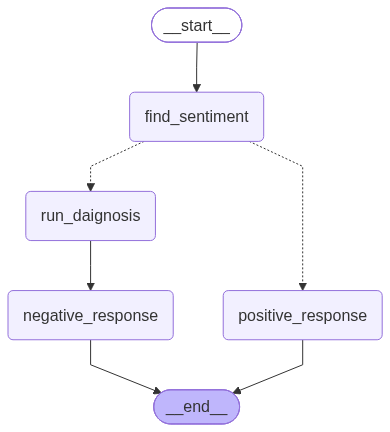

In [26]:
workflow

In [27]:
initial_state = {
    'review' : "I’ve been trying to log in for over an hour now, and the app keeps freezing on the authentication screen. I even tried reinstalling it, but no luck. This kind of bug is unacceptable, especially when it affects basic functionality."
}

final_state=workflow.invoke(initial_state)


AttributeError: 'list' object has no attribute 'sentiment'